# Plant Disease Detection Using ResNet50

**Module:** SE4050 – Deep Learning  
**Project:** Plant Disease Detection Using Deep Learning  
**Model:** ResNet50  
**Task:** Multi-Class Plant Leaf Disease Classification  

## Objective

The objective of this experiment is to evaluate the effectiveness of the
ResNet50 deep convolutional neural network for automatic plant leaf disease
classification using the PlantVillage dataset.

This notebook presents:

- Dataset exploration and analysis
- Data preprocessing
- Train/validation/test splitting
- Data augmentation
- ResNet50 architecture
- Transfer learning
- Fine-tuning
- Training performance
- Final test evaluation
- Per-class performance
- Error analysis
- Generalization analysis
- Computational efficiency
- Critical discussion

ResNet50 is one of four deep-learning architectures evaluated by the group
under comparable experimental conditions.

In [24]:
import sys

print("Python executable:")
print(sys.executable)

print("\nPython version:")
print(sys.version)

print("\nChecking packages...")

packages = [
    "numpy",
    "pandas",
    "matplotlib",
    "PIL",
    "tensorflow",
    "yaml",
    "sklearn"
]

for package in packages:
    try:
        module = __import__(package)
        version = getattr(module, "__version__", "Installed")
        print(f"✅ {package}: {version}")
    except Exception as e:
        print(f"❌ {package}: {type(e).__name__}: {e}")

Python executable:
/Users/thakkifilyas/Desktop/DL_Project/plant-disease-repo/.venv/bin/python

Python version:
3.10.11 (v3.10.11:7d4cc5aa85, Apr  4 2023, 19:05:19) [Clang 13.0.0 (clang-1300.0.29.30)]

Checking packages...
✅ numpy: 2.2.6
✅ pandas: 2.3.3
✅ matplotlib: 3.10.9
✅ PIL: 12.3.0
✅ tensorflow: 2.21.0
✅ yaml: 6.0.3
✅ sklearn: 1.7.2


In [25]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [26]:
import pandas as pd

print("Pandas version:", pd.__version__)
print("Pandas imported successfully ✅")

Pandas version: 2.3.3
Pandas imported successfully ✅


In [27]:
from pathlib import Path
import sys
import os
import json
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import tensorflow as tf
import yaml

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore")

print("Python version:", sys.version.split()[0])
print("TensorFlow version:", tf.__version__)
print("Pandas version:", pd.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

Python version: 3.10.11
TensorFlow version: 2.21.0
Pandas version: 2.3.3
Available GPUs: []


In [28]:
RANDOM_SEED = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

print("Random seed:", RANDOM_SEED)

Random seed: 42


A fixed random seed of **42** is used to improve experiment reproducibility.
The same seed should be used when generating the shared dataset split for
all models in the group comparison.

In [29]:
# Automatically determine repository root
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Change ONLY this path if the dataset is moved
DATA_DIR = Path(
    "/Users/thakkifilyas/Desktop/DL_Project/PlantVillage"
)

CONFIG_PATH = PROJECT_ROOT / "configs" / "resnet50_config.yaml"
RESULTS_DIR = PROJECT_ROOT / "results" / "resnet50"
EDA_DIR = RESULTS_DIR / "eda"
EVALUATION_DIR = RESULTS_DIR / "evaluation"

print("Project Root :", PROJECT_ROOT)
print("Dataset      :", DATA_DIR)
print("Config       :", CONFIG_PATH)
print("Results      :", RESULTS_DIR)

assert DATA_DIR.exists(), f"Dataset not found: {DATA_DIR}"
assert RESULTS_DIR.exists(), f"Results directory not found: {RESULTS_DIR}"

Project Root : /Users/thakkifilyas/Desktop/DL_Project/plant-disease-repo
Dataset      : /Users/thakkifilyas/Desktop/DL_Project/PlantVillage
Config       : /Users/thakkifilyas/Desktop/DL_Project/plant-disease-repo/configs/resnet50_config.yaml
Results      : /Users/thakkifilyas/Desktop/DL_Project/plant-disease-repo/results/resnet50


# 1. Dataset Description

The experiment uses the **PlantVillage** plant leaf image dataset.

The dataset contains images representing healthy and diseased plant leaves.
Each class directory represents a particular plant–disease or healthy
combination.

The dataset is stored locally and is not committed to GitHub because of its
size.

Before model development, exploratory data analysis is performed to examine:

- Number of classes
- Number of images
- Class distribution
- Image dimensions
- Representative samples
- Corrupted/unreadable images
- Potential class imbalance

In [31]:
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

class_dirs = sorted([
    path for path in DATA_DIR.iterdir()
    if path.is_dir()
])

class_names = [path.name for path in class_dirs]

class_df = pd.DataFrame({
    "Class ID": range(len(class_names)),
    "Class Name": class_names
})

print("Number of classes:", len(class_names))

display(class_df)

Number of classes: 15


,Class ID,Class Name
0,0,Pepper__bell___Bacterial_spot
1,1,Pepper__bell___healthy
2,2,Potato___Early_blight
3,3,Potato___Late_blight
4,4,Potato___healthy
5,5,Tomato_Bacterial_spot
6,6,Tomato_Early_blight
7,7,Tomato_Late_blight
8,8,Tomato_Leaf_Mold
9,9,Tomato_Septoria_leaf_spot


In [33]:
class_statistics = []

for class_dir in class_dirs:
    images = [
        path for path in class_dir.rglob("*")
        if path.is_file() and path.suffix.lower() in VALID_EXTENSIONS
    ]

    class_statistics.append({
        "Class Name": class_dir.name,
        "Image Count": len(images)
    })

class_counts_df = pd.DataFrame(class_statistics)

total_images = int(class_counts_df["Image Count"].sum())

class_counts_df["Percentage"] = (
    class_counts_df["Image Count"] / total_images * 100
)

class_counts_df = class_counts_df.sort_values(
    "Image Count",
    ascending=False
).reset_index(drop=True)

display(class_counts_df)

print(f"Total images: {total_images:,}")
print(f"Number of classes: {len(class_counts_df)}")

largest = class_counts_df.iloc[0]
smallest = class_counts_df.iloc[-1]

print(
    f"Largest class: {largest['Class Name']} "
    f"({largest['Image Count']} images)"
)

print(
    f"Smallest class: {smallest['Class Name']} "
    f"({smallest['Image Count']} images)"
)

,Class Name,Image Count,Percentage
0,Tomato__Tomato_YellowLeaf__Curl_Virus,402,9.635666
1,Tomato_Early_blight,364,8.724832
2,Tomato_Septoria_leaf_spot,342,8.197507
3,Tomato_Late_blight,336,8.053691
4,Potato___Late_blight,334,8.005753
5,Tomato__Tomato_mosaic_virus,312,7.478428
6,Tomato_healthy,306,7.334612
7,Tomato_Bacterial_spot,294,7.046980
8,Potato___Early_blight,282,6.759348
9,Tomato_Leaf_Mold,268,6.423778


Total images: 4,172
Number of classes: 15
Largest class: Tomato__Tomato_YellowLeaf__Curl_Virus (402 images)
Smallest class: Pepper__bell___healthy (54 images)


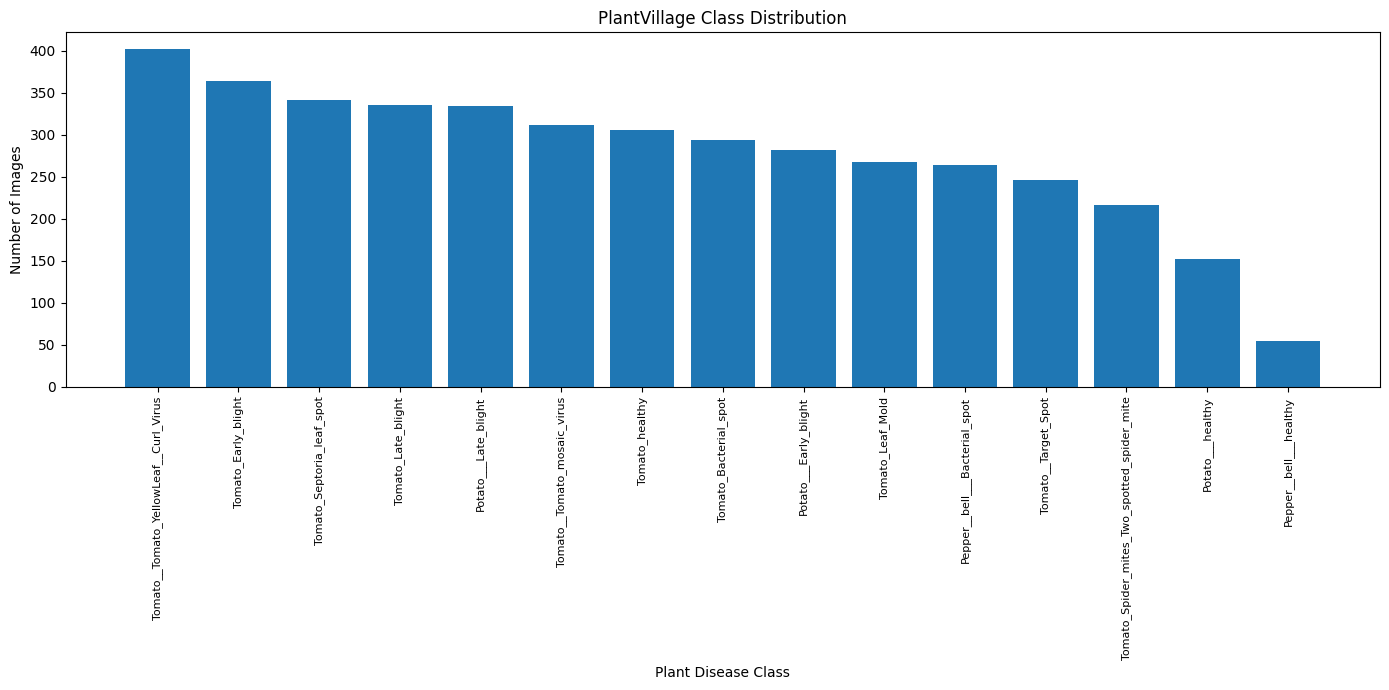

In [34]:
plt.figure(figsize=(14, 7))

plt.bar(
    class_counts_df["Class Name"],
    class_counts_df["Image Count"]
)

plt.title("PlantVillage Class Distribution")
plt.xlabel("Plant Disease Class")
plt.ylabel("Number of Images")

plt.xticks(
    rotation=90,
    fontsize=8
)

plt.tight_layout()
plt.show()

The class-distribution graph is used to identify whether some disease classes
contain substantially more training examples than others. Class imbalance can
influence model learning and per-class recall, so it is considered during
evaluation and error analysis.

In [35]:
corrupt_file = EDA_DIR / "corrupt_images.csv"

if corrupt_file.exists():
    corrupt_df = pd.read_csv(corrupt_file)

    print("Corrupted/unreadable images:", len(corrupt_df))

    if len(corrupt_df) > 0:
        display(corrupt_df)
    else:
        print("No corrupted images were recorded during EDA.")
else:
    print("No saved corruption report was found.")

Corrupted/unreadable images: 0
No corrupted images were recorded during EDA.


In [36]:
dimensions_file = EDA_DIR / "representative_dimensions.csv"

if dimensions_file.exists():
    dimensions_df = pd.read_csv(dimensions_file)

    print("Representative image dimensions:")
    display(dimensions_df)
else:
    print("Representative dimensions file was not found.")

Representative image dimensions:


,class,path,width,height,channels,mode
0,Pepper__bell___Bacterial_spot,/Users/thakkifilyas/Desktop/DL_Project/archive...,256,256,3,RGB
1,Pepper__bell___healthy,/Users/thakkifilyas/Desktop/DL_Project/archive...,256,256,3,RGB
2,Potato___Early_blight,/Users/thakkifilyas/Desktop/DL_Project/archive...,256,256,3,RGB
3,Potato___Late_blight,/Users/thakkifilyas/Desktop/DL_Project/archive...,256,256,3,RGB
4,Potato___healthy,/Users/thakkifilyas/Desktop/DL_Project/archive...,256,256,3,RGB
5,Tomato_Bacterial_spot,/Users/thakkifilyas/Desktop/DL_Project/archive...,256,256,3,RGB
6,Tomato_Early_blight,/Users/thakkifilyas/Desktop/DL_Project/archive...,256,256,3,RGB
7,Tomato_Late_blight,/Users/thakkifilyas/Desktop/DL_Project/archive...,256,256,3,RGB
8,Tomato_Leaf_Mold,/Users/thakkifilyas/Desktop/DL_Project/archive...,256,256,3,RGB
9,Tomato_Septoria_leaf_spot,/Users/thakkifilyas/Desktop/DL_Project/archive...,256,256,3,RGB


ResNet50 requires a consistent tensor shape. Therefore, input images are
resized to **224 × 224 pixels with three RGB channels** before being passed
to the network.

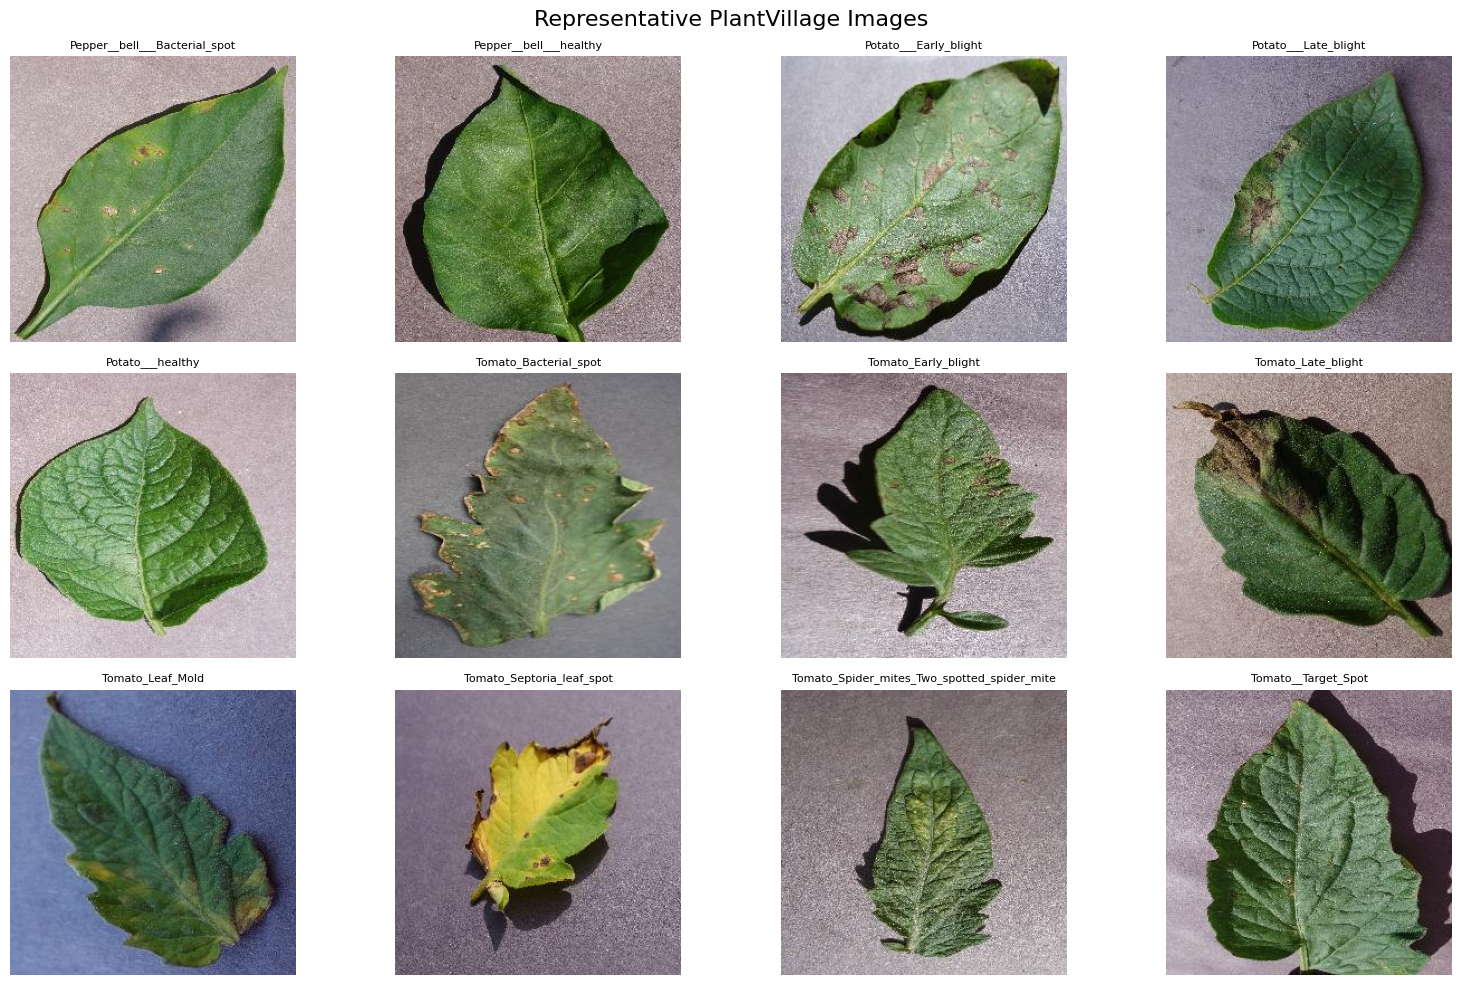

In [37]:
sample_classes = class_dirs[:min(12, len(class_dirs))]

plt.figure(figsize=(16, 10))

for index, class_dir in enumerate(sample_classes, start=1):

    images = [
        path for path in class_dir.rglob("*")
        if path.is_file() and path.suffix.lower() in VALID_EXTENSIONS
    ]

    if not images:
        continue

    image_path = images[0]

    with Image.open(image_path) as image:
        image = image.convert("RGB")

        plt.subplot(3, 4, index)
        plt.imshow(image)
        plt.title(class_dir.name, fontsize=8)
        plt.axis("off")

plt.suptitle(
    "Representative PlantVillage Images",
    fontsize=16
)

plt.tight_layout()
plt.show()

# 2. Data Preprocessing

The ResNet50 experiment uses the following preprocessing strategy:

- Input size: **224 × 224**
- Channels: **RGB**
- Transfer-learning weights: **ImageNet**
- Random seed: **42**
- Training data: preprocessing + augmentation
- Validation data: deterministic preprocessing only
- Test data: deterministic preprocessing only

Random augmentation is restricted to the training set so that validation and
test performance are measured on unchanged evaluation samples.

The test set is excluded from model training, hyperparameter selection,
early stopping, and checkpoint selection to prevent data leakage.

In [38]:
with open(CONFIG_PATH, "r") as file:
    config = yaml.safe_load(file)

print("ResNet50 configuration:")

config_table = pd.DataFrame(
    [
        {"Parameter": key, "Value": str(value)}
        for key, value in config.items()
    ]
)

display(config_table)

ResNet50 configuration:


,Parameter,Value
0,data_dir,/Users/thakkifilyas/Desktop/DL_Project/PlantVi...
1,manifest,None
2,classes,None
3,seed,42
4,image_size,"[224, 224]"
5,augmentation,True
6,batch_size,32
7,validation_split,0.15
8,test_split,0.15
9,weights,imagenet


## Dataset Splitting Strategy

A stratified dataset split is used:

| Split | Percentage | Purpose |
|---|---:|---|
| Training | 70% | Learning model parameters |
| Validation | 15% | Model selection and early stopping |
| Testing | 15% | Final unbiased evaluation |

**Random seed:** 42

Stratification is used to preserve class proportions across the training,
validation, and test subsets.

For the final group comparison, all deep-learning models should use the same
saved split/manifest so that performance differences are attributable to the
models rather than different test samples.

In [39]:
possible_manifests = [
    PROJECT_ROOT / "splits" / "shared_split.csv",
    PROJECT_ROOT / "data" / "shared_split.csv",
    RESULTS_DIR / "split_manifest.csv",
]

manifest_path = next(
    (path for path in possible_manifests if path.exists()),
    None
)

if manifest_path is not None:

    manifest_df = pd.read_csv(manifest_path)

    print("Shared manifest:", manifest_path)

    display(manifest_df.head())

    if "split" in manifest_df.columns:

        split_counts = (
            manifest_df["split"]
            .value_counts()
            .rename_axis("Split")
            .reset_index(name="Number of Images")
        )

        split_counts["Percentage"] = (
            split_counts["Number of Images"]
            / len(manifest_df)
            * 100
        )

        display(split_counts)

else:
    print(
        "No persisted shared split manifest was found in the "
        "standard project locations."
    )

No persisted shared split manifest was found in the standard project locations.


## Data Augmentation

Data augmentation is applied only to training images.

The purpose is to expose the model to reasonable variations of the original
leaf images and reduce reliance on exact image orientation or appearance.

Validation and test images are not randomly augmented, ensuring that
evaluation remains deterministic.

The exact augmentation operations used in the experiment should correspond
to the implementation in the ResNet50 data pipeline.

# 3. Experimental Design

The ResNet50 experiment follows a two-stage transfer-learning strategy.

### Stage A — Feature Extraction

The ImageNet-pretrained ResNet50 convolutional backbone is initially frozen.
Only the newly added classification head learns task-specific parameters.

### Stage B — Fine-Tuning

Later ResNet50 layers are unfrozen and trained using a smaller learning rate.
This allows higher-level ImageNet features to adapt to plant leaf disease
characteristics while reducing the risk of destroying useful pretrained
representations.

Model selection is based on validation performance. The test set is reserved
for final evaluation only.

# 4. ResNet50 Architecture

ResNet50 is a deep convolutional neural network based on **residual learning**.

A key challenge in very deep neural networks is that increasing network depth
can make optimization difficult. ResNet addresses this using **skip
connections**, which allow information to bypass one or more layers.

Conceptually, a residual block learns:

\[
y = F(x) + x
\]

where:

- \(x\) is the original input
- \(F(x)\) is the learned residual transformation
- \(y\) is the block output

These residual connections improve gradient flow and make deeper networks
easier to optimize.

ResNet50 was selected because it provides a well-established convolutional
architecture, supports ImageNet transfer learning, and provides a meaningful
architectural comparison with the other deep-learning models used by the
group.

In [40]:
SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from resnet50.model import build_resnet50

print("ResNet50 project module imported successfully.")

ResNet50 project module imported successfully.


In [46]:
import inspect

print(inspect.signature(build_resnet50))
print()
print(inspect.getsource(build_resnet50))

(num_classes, image_size=(224, 224), weights='imagenet', freeze_backbone=True, augment=False, unfreeze_from=None)

def build_resnet50(num_classes, image_size=(224,224), weights="imagenet", freeze_backbone=True, augment=False, unfreeze_from=None):
    inputs = tf.keras.Input((*image_size,3), name="image")
    x = inputs
    if augment:
        x = tf.keras.Sequential([
            tf.keras.layers.RandomFlip("horizontal"),
            tf.keras.layers.RandomRotation(0.05),
            tf.keras.layers.RandomZoom(0.10),
            tf.keras.layers.RandomTranslation(0.05, 0.05),
            tf.keras.layers.RandomContrast(0.10),
        ], name="train_augmentation")(x)
    x = tf.keras.applications.resnet50.preprocess_input(x)
    backbone = tf.keras.applications.ResNet50(include_top=False, weights=weights, input_tensor=x)
    backbone.trainable = not freeze_backbone
    if freeze_backbone and unfreeze_from:
        backbone.trainable = True
        for layer in backbone.layers:
            l

In [49]:
model.summary()

total_parameters = model.count_params()

trainable_parameters = int(
    np.sum([
        np.prod(variable.shape)
        for variable in model.trainable_weights
    ])
)

non_trainable_parameters = (
    total_parameters - trainable_parameters
)

parameter_df = pd.DataFrame({
    "Parameter Type": [
        "Total Parameters",
        "Trainable Parameters",
        "Non-Trainable Parameters"
    ],
    "Count": [
        total_parameters,
        trainable_parameters,
        non_trainable_parameters
    ]
})

display(parameter_df)

NameError: name 'model' is not defined